# SAMPIC event-builder recording QA

Checks **BD00 v4**, **BTnn v1**, and **BC00 v1**, and **BS00 v1** from the two-crate simulator through the actual unpacker and ROOT persistence. Legacy SD/ST/SC branches remain separate. Run with `root_env` after `tests/verify_builder_banks.py`.

BD hits contain `crate`, `data` (the same corrected SD fields), and `metadata` (the same advanced SH fields). `data.encoded_waveform` preserves signed int16 wire values; `data.corrected_waveform` is in **volts when ADC correction is enabled**, otherwise ADC counts. First-cell and physical-cell-zero timestamps retain their original **double nanoseconds**, including fractional parts. Event boundaries remain uint64 collection bounds, whose clock depends on the ODB collection strategy.

The simulator generates a positive pulse with Gaussian noise, amplitude variation and trigger jitter. This is a software format/QA test, not a test of hardware calibration accuracy. Every sample and timing field is checked independently against MIDAS bytes by the verification script; this notebook adds bank-layout printouts, accounting, correction/precision checks and plots.

BS00 contains per-cycle cut counters, enabled states and signed priorities. Lower priorities run first (ID breaks ties); later cuts only see survivors. Disabled cuts report zero. Cuts remove hits while preserving event headers. Legacy `rejected_events` counts payloads modified by a cut; `rejected_hits` counts removed hits. The checks support cuts that remove every hit and timing-disabled runs.

The current QA uses `periodic_readout`: collection closes on the host steady clock, independently of SAMPIC timestamps. Strategy settings are printed from the recorded ODB snapshot under `Settings/Collection_strategies`. Cuts remain independently configured under `Settings/Selection`. Periodic BC/BS accounting now spans each completed readout window; every periodic window has BD, including header-only BD for empty or fully cut payloads. Set `DATASET` below to compare fresh recordings with all cuts disabled or the dummy cut enabled.


In [1]:
# Switch between "dummy_cut" (clear every third nonempty payload) and "no_cuts".
DATASET = "no_cuts"
QA_DIRECTORY = "/home/jack/cpp_projects/analysis_pipeline_project/apps/midas_file_unpacker_app/.artifacts/qa_comparison"
DATA_FILE = f"{QA_DIRECTORY}/{DATASET}/output.root"
MANIFEST_FILE = f"{QA_DIRECTORY}/{DATASET}/manifest.json"


In [2]:
from pathlib import Path
import json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ROOT
from IPython.display import display

ROOT.gROOT.SetBatch(True)
DATA_FILE = Path(DATA_FILE).expanduser().resolve()
MANIFEST_FILE = Path(MANIFEST_FILE).expanduser().resolve()
APP = next(p for p in [Path.cwd(), *Path.cwd().parents, *DATA_FILE.parents]
           if (p / "config/unpacker_pipelines/SAMPIC").is_dir())
for name in ["unpacker_data_products_core", "unpacker_data_products_sampic"]:
    assert ROOT.gSystem.Load(str(APP / "build/lib" / f"lib{name}.so")) >= 0
manifest = json.loads(MANIFEST_FILE.read_text())
COLLECTION_STRATEGY = manifest["configuration"].get("collection_strategy", "time_grouping")
print("Collection strategy:", COLLECTION_STRATEGY)
odb_file = Path(manifest["file"]).parents[1] / "odb.json"
if odb_file.is_file():
    builder_settings = json.loads(odb_file.read_text())["Equipment"]["SAMPIC Builder"]["Settings"]
    collection_settings = builder_settings.get("Collection_strategies")
    if collection_settings:
        print("Recorded Settings/Collection_strategies:", json.dumps(collection_settings,indent=2))
        assert collection_settings["Active strategy"] == COLLECTION_STRATEGY
        assert set(["time_grouping","fixed_time_bins","periodic_readout"]).issubset(collection_settings)
        if COLLECTION_STRATEGY == "periodic_readout":
            assert collection_settings["periodic_readout"]["Period ns"] == manifest["configuration"]["period_ns"]
FIGURES = DATA_FILE.parent / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
def save_figure(fig, name):
    fig.tight_layout()
    for extension in ["png", "pdf"]:
        fig.savefig(FIGURES / f"{name}.{extension}", bbox_inches="tight")
    plt.show()


Collection strategy: periodic_readout
Recorded Settings/Collection_strategies: {
  "time_grouping": {
    "Event window ns": 200,
    "Allowed lateness ns": 2000
  },
  "Active strategy": "periodic_readout",
  "periodic_readout": {
    "Period ns": 10000000
  },
  "fixed_time_bins": {
    "Bin width ns": 10000,
    "Bin origin ns": 0,
    "Allowed lateness ns": 1000000,
    "Emit empty bins": true,
    "Maximum bins per build": 256
  }
}


In [3]:
summary_fields = "cycle_id read_count hit_count prepare_us_sum read_us_sum decode_us_sum total_us_sum prepare_us_max read_us_max decode_us_max total_us_max retries_sum retries_max first_acquisition_id last_acquisition_id".split()
cycle_fields = "cycle_id start_ns input_events input_hits output_events output_hits selected_events rejected_events input_read_ns group_build_ns cuts_ns finalize_ns output_wait_ns total_ns flags".split()
file = ROOT.TFile.Open(str(DATA_FILE))
assert file and not file.IsZombie(), DATA_FILE
tree = file.Get("events")
assert tree and tree.GetBranch("sampic_builder_event") and tree.GetBranch("sampic_builder_diagnostics")
hits, events, summaries, cycles, cuts = [], [], [], [], []
counts = Counter()
for row in tree:
    assert not row.has_sampic_event and not row.has_sampic_event_timing and not row.has_sampic_collector_timing
    if row.has_sampic_builder_event:
        event = row.sampic_builder_event
        events.append(dict(start_ns=int(event.start_ns), end_ns=int(event.end_ns), hits=len(event.hits)))
        counts["BD00"] += 1
        for hit in event.hits:
            data, metadata = hit.data, hit.metadata
            encoded = np.array(list(data.encoded_waveform), dtype=np.int16)
            waveform = np.array(list(data.corrected_waveform), dtype=np.float64)
            flags = ord(data.flags) if isinstance(data.flags, str) else int(data.flags)
            assert len(encoded) == len(waveform) <= 64
            assert np.allclose(waveform, encoded/(10000 if data.adc_corrected else 1), rtol=1e-7, atol=1e-8)
            hits.append(dict(crate=int(hit.crate), board=int(data.fe_board_index), channel=int(data.channel),
                             hit_number=int(data.hit_number), flags=flags,
                             adc_corrected=bool(data.adc_corrected),
                             timestamp_ns=float(data.first_cell_timestamp),
                             physical_cell0_timestamp_ns=float(metadata.physical_cell0_timestamp_ns),
                             sampic_timestamp_a=int(metadata.sampic_timestamp_a),
                             sampic_timestamp_b=int(metadata.sampic_timestamp_b),
                             fpga_timestamp=int(metadata.fpga_timestamp),
                             trigger_position_mask=int(metadata.trigger_position_mask),
                             samples=len(waveform), encoded_waveform=encoded, waveform=waveform))
    if row.has_sampic_builder_diagnostics:
        diag = row.sampic_builder_diagnostics
        for summary in diag.acquisition_summaries:
            summaries.append(dict(crate=int(summary.crate), **{key:int(getattr(summary,key)) for key in summary_fields}))
            counts[f"BT{int(summary.crate):02d}"] += 1
        if diag.has_cut_summary:
            for cut in diag.cut_summaries:
                cuts.append(dict(cycle_id=int(diag.cut_cycle_id),id=str(cut.id),enabled=bool(cut.enabled),priority=int(cut.priority),
                                 **{key:int(getattr(cut,key)) for key in ["evaluated_events","rejected_events","evaluated_hits","rejected_hits"]}))
            counts["BS00"] += 1
        if diag.has_collector_cycle:
            cycles.append({key:int(getattr(diag.collector_cycle,key)) for key in cycle_fields})
            counts["BC00"] += 1
file.Close()
hits = pd.DataFrame(hits, columns=["crate","board","channel","hit_number","flags","adc_corrected","timestamp_ns",
                                   "physical_cell0_timestamp_ns","sampic_timestamp_a","sampic_timestamp_b","fpga_timestamp",
                                   "trigger_position_mask","samples","encoded_waveform","waveform"])
for key in ["crate","board","channel","flags","samples"]: hits[key]=hits[key].astype("int64")
for key in ["timestamp_ns","physical_cell0_timestamp_ns"]: hits[key]=hits[key].astype(float)
hits["adc_corrected"]=hits.adc_corrected.astype(bool)
events = pd.DataFrame(events,columns=["start_ns","end_ns","hits"])
summaries = pd.DataFrame(summaries,columns=["crate",*summary_fields]).astype("uint64")
cycles = pd.DataFrame(cycles,columns=cycle_fields).astype("uint64")
cuts = pd.DataFrame(cuts,columns=["cycle_id","id","enabled","priority","evaluated_events","rejected_events","evaluated_hits","rejected_hits"])
assert not cuts.empty, "No BS00 selection summaries in this recording"
print(f"Loaded {len(events):,} physics events, {len(hits):,} waveforms, {len(cycles):,} timing cycles, {counts['BS00']:,} cut-summary cycles")


Loaded 1,058 physics events, 155,712 waveforms, 1,058 timing cycles, 1,058 cut-summary cycles


## Bank structure and decoded examples

Offsets and sizes below describe the actual MIDAS payload. ROOT stores SD fields under `hit.data` and SH fields under `hit.metadata`; corrected floating waveforms are derived from the signed wire samples.


In [4]:
# Wire offsets exclude MIDAS framing. Layouts are independently asserted below.
import struct
import hashlib
import sys
sys.path.insert(0, str(APP / "tests"))
from verify_current_banks import events as midas_events
source_file = Path(manifest["file"])
assert hashlib.sha256(source_file.read_bytes()).hexdigest() == manifest["sha256"]
assert struct.calcsize("<IHHIQQ") == 28
assert 2 + struct.calcsize("<BBi6B64hHfd") + struct.calcsize("<diiQQ") == 188
assert struct.calcsize("<4sHH15Q") == 128

def print_layout(title, rows):
    print("\n" + title)
    print(pd.DataFrame(rows, columns=["Offset", "Field", "Type", "Bytes", "Units / meaning"]).to_string(index=False))

print_layout("BD00 v4: 28-byte event header", [
    (0,"magic","char[4]",4,"SEB1"),(4,"version","uint16",2,"4"),
    (6,"reserved","uint16",2,"0"),(8,"waveform_count","uint32",4,"hits"),
    (12,"start_ns","uint64",8,"collection clock ns"),(20,"end_ns","uint64",8,"collection clock ns")])
print_layout("BD00: each hit is 188 bytes (crate + SD + SH); offsets relative to hit start", [
    (0,"crate","uint16",2,"source crate"),(2,"data.fe_board_index","uint8",1,"FEB 0..3"),
    (3,"data.channel","uint8",1,"FEB channel 0..63"),(4,"data.hit_number","int32",4,"vendor-event-local ID"),
    (8,"data.sampic_index","uint8",1,"0..3"),(9,"data.channel_index","uint8",1,"0..15"),
    (10,"valid sample count","uint8",1,"0..64"),(11,"data.flags","uint8",1,"corrections and quality bits"),
    (12,"data.cell_info","uint8",1,"0..63"),(13,"data.first_cell_physical_index","uint8",1,"0..63"),
    (14,"data.encoded_waveform","int16[64]",128,"0.1 mV/count if ADC-corrected; otherwise ADC counts"),
    (142,"data.raw_tot_value","uint16",2,"ADC counts"),(144,"data.tot_value","float32",4,"ns"),
    (148,"data.first_cell_timestamp","float64",8,"hardware ns, fractional precision retained"),
    (156,"metadata.physical_cell0_timestamp_ns","float64",8,"hardware ns"),
    (164,"metadata.sampic_timestamp_a","int32",4,"hardware counter"),
    (168,"metadata.sampic_timestamp_b","int32",4,"hardware counter"),
    (172,"metadata.fpga_timestamp","uint64",8,"hardware counter"),
    (180,"metadata.trigger_position_mask","uint64",8,"bit i = sample i trigger flag")])
print("SD flag bits: 0 INL-corrected; 1 ADC-corrected; 2 residual-pedestal-corrected; "
      "3 waveform clipped; 4 waveform nonfinite; 5 raw ToT clipped")
for bank, magic, names in [("BTnn","BTS1",summary_fields),("BC00","BCT1",cycle_fields)]:
    rows=[(0,"magic","char[4]",4,magic),(4,"version","uint16",2,"1"),(6,"record_size","uint16",2,"128")]
    for i,name in enumerate(names):
        units="microseconds" if "_us_" in name else "nanoseconds" if name.endswith("_ns") else "bit 0: EOR flush" if name=="flags" else "ID/count"
        rows.append((8+8*i,name,"uint64",8,units))
    print_layout(f"{bank}: 128-byte timing record",rows)
print_layout("BS00 v1: 24-byte cut-summary header", [
    (0,"magic","char[4]",4,"BSS1"),(4,"version","uint16",2,"1"),(6,"record_size","uint16",2,"72"),
    (8,"cycle_id","uint64",8,"joins BC/BT when enabled"),(16,"cut_count","uint32",4,"registered cuts"),
    (20,"reserved","uint32",4,"0")])
print_layout("BS00: each cut is 72 bytes; records in effective evaluation order",[
    (0,"id","char[32]",32,"NUL-padded stable cut name"),(32,"enabled","uint32",4,"0/1"),
    (36,"priority","int32",4,"lower first, then ID"),(40,"evaluated_events","uint64",8,"events reaching enabled cut"),
    (48,"rejected_events","uint64",8,"payloads modified by this cut"),(56,"evaluated_hits","uint64",8,"hits in evaluated events"),
    (64,"rejected_hits","uint64",8,"hits removed by this cut")])
print("MIDAS framing: 16-byte event header + 8-byte bank container + 12 bytes per BANK32 header + 0..7 alignment bytes per bank.")
inventory={}; example_header=None
for serial,banks in midas_events(source_file):
    for bank,payload in banks.items():
        inventory.setdefault(bank,[]).append(len(payload))
        if bank=="BD00" and example_header is None:
            magic,version,reserved,count,start,end=struct.unpack_from("<4sHHIQQ",payload)
            example_header=dict(bank=bank,magic=magic.decode(),version=version,waveform_count=count,start_ns=start,end_ns=end,payload_bytes=len(payload))
print("\nObserved bank payloads (excluding MIDAS framing):")
print(pd.DataFrame([dict(bank=bank,records=len(sizes),min_bytes=min(sizes),max_bytes=max(sizes)) for bank,sizes in sorted(inventory.items())]).to_string(index=False))
print("\nExample BD header:", json.dumps(example_header,indent=2))
if not hits.empty:
    example=hits.iloc[0]
    print("\nExample decoded hit:", json.dumps({key:(value.item() if isinstance(value,np.generic) else value) for key,value in example.items() if key not in ["waveform","encoded_waveform"]},indent=2))
    print("First 8 encoded samples:", example.encoded_waveform[:8].tolist())
    print("First 8 corrected samples (V):", example.waveform[:8].tolist())
else:
    print("No retained hits: event headers are still preserved.")
if not summaries.empty: print("\nExample BT record:", summaries.iloc[0].to_json(indent=2))
if not cycles.empty: print("\nExample BC record:", cycles.iloc[0].to_json(indent=2))
print("\nExample BS records:\n", cuts[cuts.cycle_id==cuts.iloc[0].cycle_id].to_string(index=False))



BD00 v4: 28-byte event header
 Offset          Field    Type  Bytes     Units / meaning
      0          magic char[4]      4                SEB1
      4        version  uint16      2                   4
      6       reserved  uint16      2                   0
      8 waveform_count  uint32      4                hits
     12       start_ns  uint64      8 collection clock ns
     20         end_ns  uint64      8 collection clock ns

BD00: each hit is 188 bytes (crate + SD + SH); offsets relative to hit start
 Offset                                Field      Type  Bytes                                     Units / meaning
      0                                crate    uint16      2                                        source crate
      2                  data.fe_board_index     uint8      1                                            FEB 0..3
      3                         data.channel     uint8      1                                   FEB channel 0..63
      4                      

## Accounting, cuts and continuity

All input hits must be accounted for as either retained BD waveforms or rejected hits in BS. BT summaries cover source acquisitions independently of cuts. BS records per-cycle deltas, not cumulative totals. Timing banks can be disabled; BS remains available. The simulator currently emits integer-valued first-cell times; separate edge-case fixtures verify fractional double timestamps and full-width counters.


In [5]:
expected = manifest["validation"]
assert dict(counts) == expected["bank_counts"]
actual_hits = {str(crate): int(n) for crate,n in hits.groupby("crate").size().items()}
actual_reads = {f"BT{int(crate):02d}": int(n) for crate,n in summaries.groupby("crate")["read_count"].sum().items()}
assert actual_hits == expected["waveforms_by_crate"]
assert actual_reads == expected["acquisition_reads_by_bank"]
assert (hits.samples == manifest["configuration"]["samples"]).all()
cut_fields=["evaluated_events","rejected_events","evaluated_hits","rejected_hits"]
cut_totals=cuts.groupby("id",sort=False)[cut_fields].sum()
assert {str(name):{key:int(row[key]) for key in cut_fields} for name,row in cut_totals.iterrows()} == expected["cut_totals"]
assert (cuts.rejected_events<=cuts.evaluated_events).all() and (cuts.rejected_hits<=cuts.evaluated_hits).all()
assert not cuts.duplicated(["cycle_id","id"]).any()
assert (cuts.loc[~cuts.enabled,cut_fields]==0).all().all()
assert (cuts.groupby("id").priority.nunique()==1).all() and (cuts.groupby("id").enabled.nunique()==1).all()
if not cycles.empty:
    assert cycles.cycle_id.is_unique and cycles.cycle_id.is_monotonic_increasing
    assert summaries.cycle_id.isin(cycles.cycle_id).all() and cuts.cycle_id.isin(cycles.cycle_id).all()
    assert int(cycles.input_hits.sum()) == len(hits)+int(cut_totals.rejected_hits.sum())
    assert int(cycles.output_hits.sum()) == len(hits)
    assert int(cycles.rejected_events.sum()) <= int(cut_totals.rejected_events.sum())
    assert int(cycles.input_events.sum()) == int(summaries.read_count.sum())
    assert int(cycles.output_events.sum()) == len(events)
    by_cycle=cycles.set_index("cycle_id")
for cycle,group in cuts.groupby("cycle_id",sort=False):
    order=list(zip(group.priority,group.id)); assert order==sorted(order)
    remaining_events=None; remaining_hits=None
    if not cycles.empty:
        record=by_cycle.loc[cycle]
        remaining_events=int(record.selected_events)+int(record.rejected_events)
    for cut in group.itertuples():
        if not cut.enabled: continue
        if remaining_events is not None: assert cut.evaluated_events<=remaining_events
        if remaining_hits is not None: assert cut.evaluated_hits==remaining_hits
        remaining_events=cut.evaluated_events
        remaining_hits=cut.evaluated_hits-cut.rejected_hits
    if not cycles.empty:
        if remaining_events is not None: assert remaining_events<=int(record.output_events)
        if remaining_hits is not None: assert remaining_hits==int(record.output_hits)
if not summaries.empty:
    assert int(summaries.hit_count.sum())==len(hits)+int(cut_totals.rejected_hits.sum())
for crate,group in summaries.groupby("crate"):
    group=group.sort_values("cycle_id")
    assert int(group.iloc[0].first_acquisition_id)==0
    assert (group.last_acquisition_id-group.first_acquisition_id+1==group.read_count).all()
    assert (group.first_acquisition_id.to_numpy()[1:]==group.last_acquisition_id.to_numpy()[:-1]+1).all()
    assert (group.read_us_max<=group.read_us_sum).all()
if manifest["configuration"].get("dummy_enabled"):
    row=cut_totals.loc["dummy"]
    assert int(row.rejected_events)==int(row.evaluated_events)//manifest["configuration"]["dummy_every"]
display(cut_totals)
assert hits.adc_corrected.all()
assert (hits["flags"] & (8|16|32) == 0).all()
assert np.isfinite(hits.timestamp_ns).all() and np.isfinite(hits.physical_cell0_timestamp_ns).all()
print("PASS: retained + rejected hit accounting, per-cut ordering/counters, acquisition continuity, corrected sample scaling and double timestamps")

if COLLECTION_STRATEGY == "periodic_readout" and not cycles.empty:
    assert len(events) == len(cycles) == counts["BS00"]
    assert (cycles.output_events == 1).all()
    print(f"Periodic envelopes preserved: {len(events)} BD = BC = BS; {(events.hits == 0).sum()} empty payloads")


,evaluated_events,rejected_events,evaluated_hits,rejected_hits
id,,,,
topology,0,0,0,0
dummy,0,0,0,0


PASS: retained + rejected hit accounting, per-cut ordering/counters, acquisition continuity, corrected sample scaling and double timestamps
Periodic envelopes preserved: 1058 BD = BC = BS; 28 empty payloads


## Cut configuration and rejection counts

Counters are summed from BS00 deltas; disabled cuts have zero evaluated events. Priorities determine which survivors reach each cut.


,enabled,priority,evaluated_events,rejected_events,evaluated_hits,rejected_hits
id,,,,,,
topology,False,100,0,0,0,0
dummy,False,200,0,0,0,0


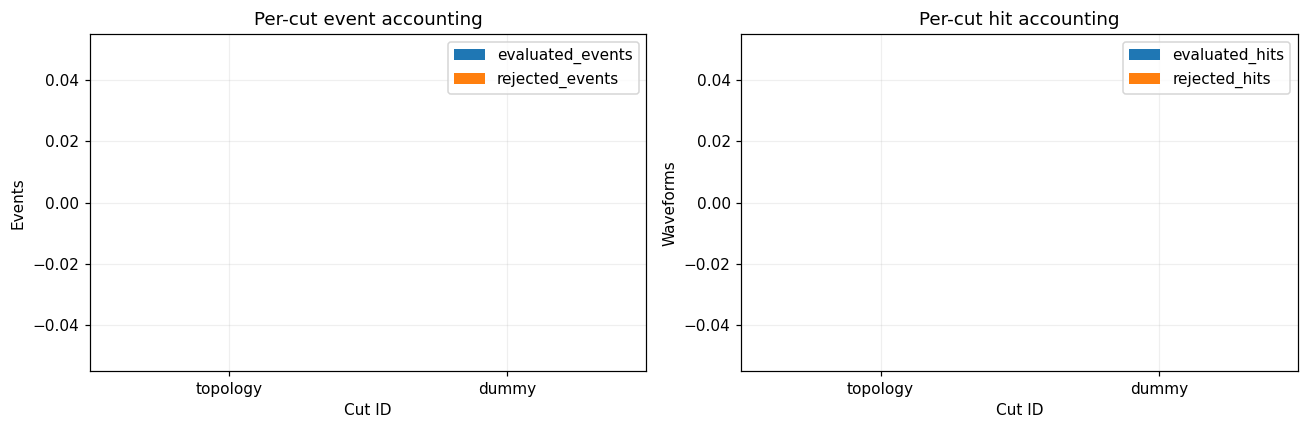

In [6]:
configuration=cuts.groupby("id",sort=False)[["enabled","priority"]].first()
display(configuration.join(cut_totals))
fig,axes=plt.subplots(1,2,figsize=(12,4))
cut_totals[["evaluated_events","rejected_events"]].plot.bar(ax=axes[0],rot=0)
cut_totals[["evaluated_hits","rejected_hits"]].plot.bar(ax=axes[1],rot=0)
axes[0].set(ylabel="Events",title="Per-cut event accounting",xlabel="Cut ID")
axes[1].set(ylabel="Waveforms",title="Per-cut hit accounting",xlabel="Cut ID")
save_figure(fig,"selection_cut_summaries")


## Signal shapes and channel coverage

Example traces should show a positive pulse near sample 17 on a noisy baseline. The simulator mixes low-amplitude punch-through tracks with larger pulses; cuts are disabled, so both populations should be present. This is a visual check of the existing generator, not a fitted signal-recovery test.

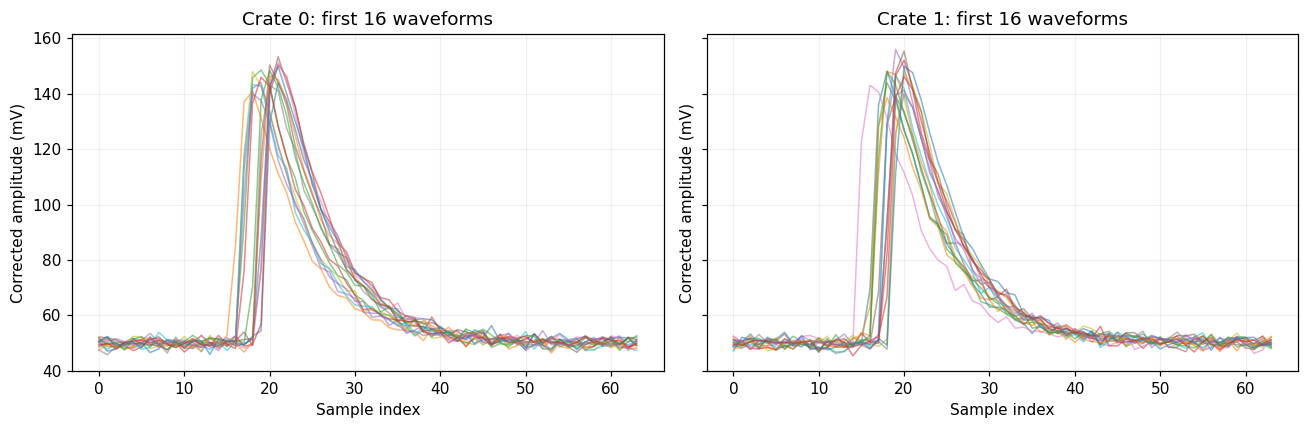

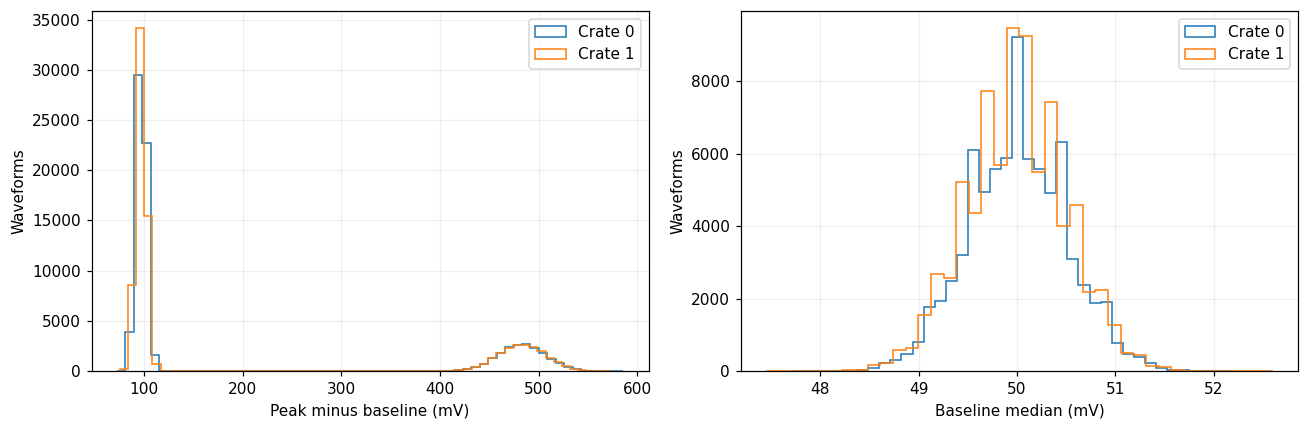

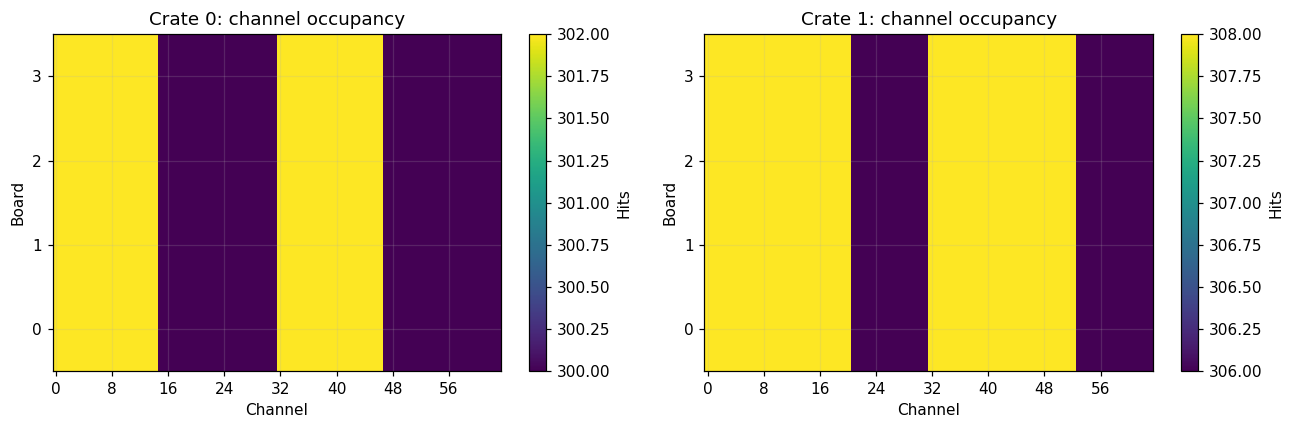

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, crate in zip(axes, sorted(hits.crate.unique())):
    subset = hits[hits.crate == crate]
    for wave in subset.waveform.iloc[:16]:
        ax.plot(np.arange(len(wave)), wave*1000, alpha=0.55, linewidth=1)
    ax.set(title=f"Crate {crate}: first 16 waveforms", xlabel="Sample index", ylabel="Corrected amplitude (mV)")
save_figure(fig, "waveform_examples")

hits["baseline_mV"] = hits.waveform.map(lambda wave: float(np.median(wave[:12]))*1000).astype(float)
hits["peak_above_baseline_mV"] = hits.waveform.map(lambda wave: float(wave.max())*1000).astype(float) - hits.baseline_mV
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for crate, group in hits.groupby("crate"):
    axes[0].hist(group.peak_above_baseline_mV, bins=60, histtype="step", label=f"Crate {crate}")
    axes[1].hist(group.baseline_mV, bins=40, histtype="step", label=f"Crate {crate}")
axes[0].set(xlabel="Peak minus baseline (mV)", ylabel="Waveforms")
axes[1].set(xlabel="Baseline median (mV)", ylabel="Waveforms")
for ax in axes: ax.legend()
save_figure(fig, "signal_distributions")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (crate, group) in zip(axes, hits.groupby("crate")):
    occupancy = group.groupby(["board", "channel"]).size().unstack(fill_value=0)
    image = ax.imshow(occupancy.to_numpy(), aspect="auto", origin="lower")
    ax.set(title=f"Crate {crate}: channel occupancy", xlabel="Channel", ylabel="Board")
    ax.set_xticks(np.arange(len(occupancy.columns))[::max(1,len(occupancy.columns)//8)], occupancy.columns[::max(1,len(occupancy.columns)//8)])
    ax.set_yticks(np.arange(len(occupancy.index)), occupancy.index)
    fig.colorbar(image, ax=ax, label="Hits")
save_figure(fig, "channel_occupancy")


## Event building and acquisition timing

The event bounds use the configured collection clock (hardware grouping/binning or host-relative periodic collection). Individual hit timestamps are hardware doubles and are preserved independently of those bounds. Source read durations in BTnn are microseconds and must not be subtracted from hardware timestamps.


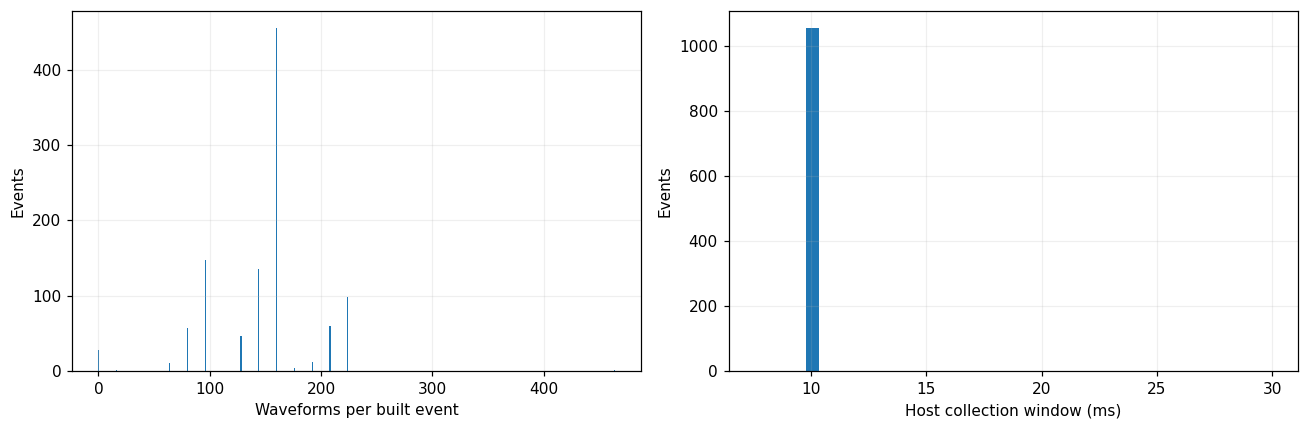

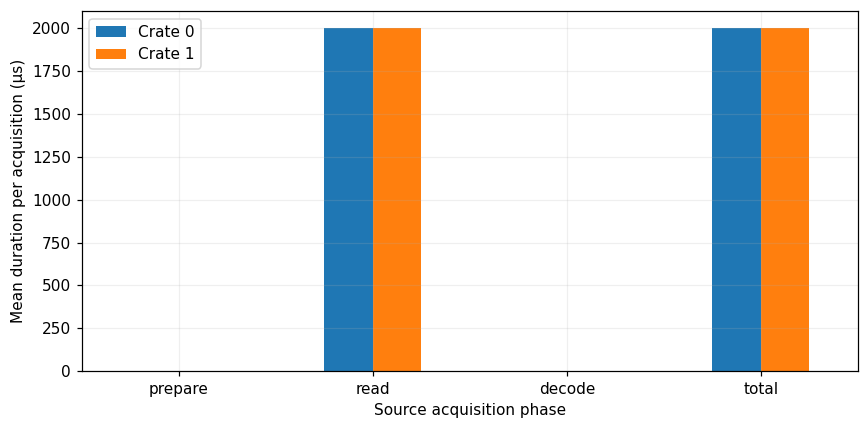

,Crate 0,Crate 1
prepare,0.0,0.0
read,2000.0,2000.0
decode,0.0,0.0
total,2000.0,2000.0


Total retries: 0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if not events.empty:
    axes[0].hist(events.hits, bins=np.arange(events.hits.min(), events.hits.max()+2)-0.5)
else: axes[0].text(0.5,0.5,"No retained events",ha="center",transform=axes[0].transAxes)
axes[0].set(xlabel="Waveforms per built event", ylabel="Events")
span=(events.end_ns-events.start_ns).astype(float)
if COLLECTION_STRATEGY=="periodic_readout": span=span/1e6
axes[1].hist(span,bins=40)
axes[1].set(xlabel="Host collection window (ms)" if COLLECTION_STRATEGY=="periodic_readout" else "Collection interval span (ns)",ylabel="Events")
save_figure(fig, "built_event_sizes")

phases = ["prepare", "read", "decode", "total"]
means = pd.DataFrame({crate: [group[f"{phase}_us_sum"].sum()/group.read_count.sum() for phase in phases]
                      for crate,group in summaries.groupby("crate")}, index=phases)
means.columns = [f"Crate {crate}" for crate in means.columns]
fig, ax = plt.subplots(figsize=(8,4))
if means.shape[1]: means.plot.bar(ax=ax, rot=0)
else: ax.text(0.5,0.5,"Acquisition timing disabled",ha="center",transform=ax.transAxes)
ax.set(xlabel="Source acquisition phase", ylabel="Mean duration per acquisition (µs)")
save_figure(fig, "acquisition_phase_timings")
display(means)
print("Total retries:", int(summaries.retries_sum.sum()))


## Builder-cycle timing

BC00 input counts and durations describe active collection cycles, excluding empty idle polls. Total time ends before the diagnostic event is constructed/sent. Output-wait includes physics output submission. These measurements can show software stalls but are not a sustained throughput benchmark at this low simulation rate.

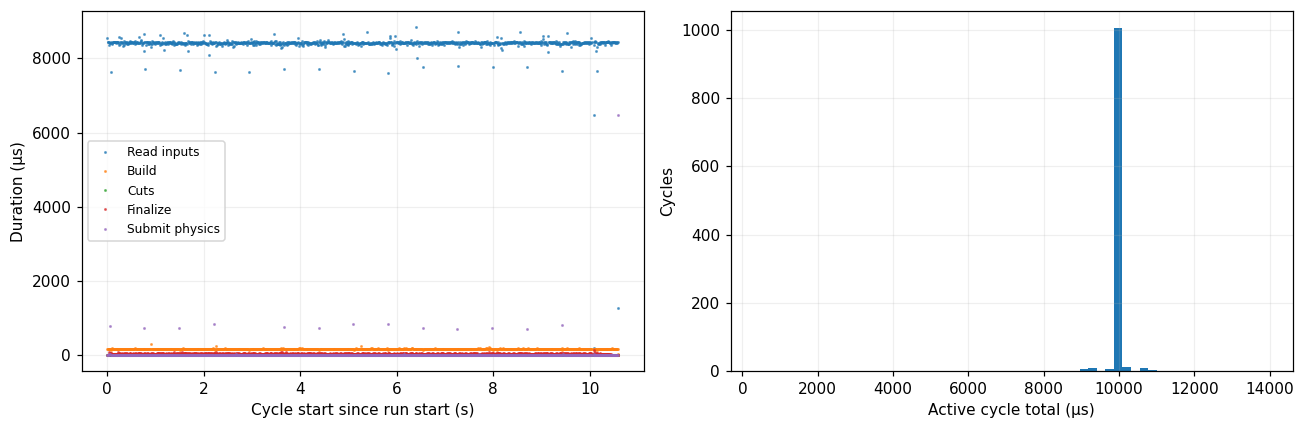

End-of-run flush cycles: 1
Figures saved to /home/jack/cpp_projects/analysis_pipeline_project/apps/midas_file_unpacker_app/.artifacts/qa_comparison/no_cuts/figures


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for field, label in [("input_read_ns","Read inputs"),("group_build_ns","Build"),("cuts_ns","Cuts"),("finalize_ns","Finalize"),("output_wait_ns","Submit physics")]:
    axes[0].plot(cycles.start_ns/1e9, cycles[field]/1e3, ".", markersize=2, alpha=0.6, label=label)
axes[0].set(xlabel="Cycle start since run start (s)", ylabel="Duration (µs)")
axes[0].legend(fontsize=8)
axes[1].hist(cycles.total_ns/1e3, bins=60)
axes[1].set(xlabel="Active cycle total (µs)", ylabel="Cycles")
save_figure(fig, "builder_cycle_timings")
print("End-of-run flush cycles:", int(((cycles["flags"] & 1) != 0).sum()))
print("Figures saved to", FIGURES)
